# SismoNexo Colombia — análisis exploratorio del catálogo

**Autor:** Johan Antonio Peña López · Institución Universitaria EAM

Este cuaderno explora el catálogo limpio (`data/processed/events.parquet`) generado por el pipeline a partir del catálogo público de la Red Sismológica Nacional de Colombia (Servicio Geológico Colombiano). Todo lo que aparece aquí son registros reales.

> No constituye una alerta oficial ni predice terremotos individuales.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
ev = pd.read_parquet(ROOT / "data/processed/events.parquet")
audit = json.loads((ROOT / "data/processed/audit.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
print(f"Versión del conjunto de datos: {audit['dataset_version']}")
print(f"{len(ev):,} eventos · {ev.event_datetime_utc.min():%Y-%m-%d} a {ev.event_datetime_utc.max():%Y-%m-%d} · {ev.shape[1]} columnas".replace(",", "."))
ev[["event_id", "event_datetime_utc", "latitude", "longitude", "depth_km", "magnitude", "magnitude_type", "department", "quality_code"]].tail()

Versión del conjunto de datos: rsnc-2026.10.10-094f0852
66.987 eventos · 1993-06-01 a 2026-10-10 · 31 columnas


,event_id,event_datetime_utc,latitude,longitude,depth_km,magnitude,magnitude_type,department,quality_code
66982,SGC2026tyidhy,2026-10-10 08:43:30+00:00,7.178,-79.980,30.00,3.1,M,,C
66983,SGC2026tyijkd,2026-10-10 08:50:32+00:00,3.877,-75.631,18.97,2.5,MLr_2,Tolima,A
66984,SGC2026tylfmx,2026-10-10 10:16:33+00:00,4.469,-76.705,42.94,3.4,MLr_1,Chocó,A
66985,SGC2026tynxeq,2026-10-10 11:37:28+00:00,10.343,-74.617,30.91,2.6,MLr_4,Magdalena,B
66986,SGC2026tysfkx,2026-10-10 13:46:54+00:00,7.419,-80.560,0.00,4.8,M_Pac,,B


## 1. Registro de auditoría de la limpieza

Cada regla, cuántas filas afecta y cuántas descarta. Solo se eliminan duplicados.

In [2]:
pd.DataFrame(audit["audit"])[["rule", "title", "action", "rows_in", "rows_affected", "rows_dropped", "rows_out"]]

,rule,title,action,rows_in,rows_affected,rows_dropped,rows_out
0,R01,Fecha y hora en UTC (ISO 8601),descartar,67140,0,0,67140
1,R02,Conversión de campos numéricos,transformar,67140,67140,0,67140
2,R03,Coordenadas válidas dentro de la ventana de es...,descartar,67140,0,0,67140
3,R04,Magnitud reportada,descartar,67140,0,0,67140
4,R05,Duplicados por identificador,descartar,67140,35,35,67105
5,R06,Duplicados aproximados,descartar,67105,118,118,66987
6,R07,"Profundidad faltante, fuera de rango o fijada ...",marcar,66987,4248,0,66987
7,R08,Familia del tipo de magnitud,transformar,66987,66987,0,66987
8,R09,Departamento y municipio por unión espacial (D...,enriquecer,66987,59633,0,66987
9,R10,Descripción de ubicación,transformar,66987,48820,0,66987


## 2. Cobertura temporal y cambio de sistema

En marzo de 2018 el SGC pasó de SEISAN a SeisComP. Las series que cruzan esa fecha no son estrictamente homogéneas.

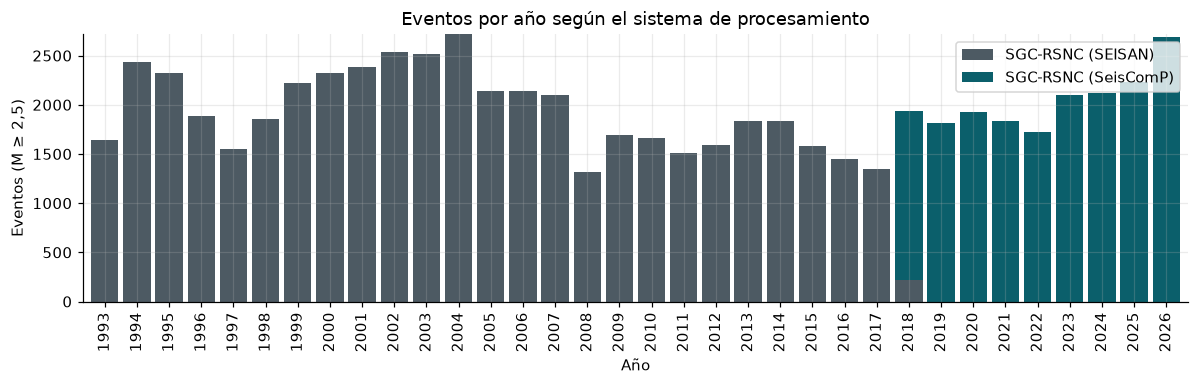

El último año está incompleto: el catálogo termina el 2026-10-10


In [3]:
ev["year"] = ev.event_datetime_utc.dt.year
by = ev.groupby(["year", "source"]).size().unstack(fill_value=0)
ax = by.plot(kind="bar", stacked=True, figsize=(11, 3.6), color=["#4d5a63", "#0b5f6b"], width=0.85)
ax.set(xlabel="Año", ylabel="Eventos (M ≥ 2,5)", title="Eventos por año según el sistema de procesamiento")
ax.legend(title="")
plt.tight_layout(); plt.show()
print("El último año está incompleto: el catálogo termina el", ev.event_datetime_utc.max().date())

## 3. Magnitud: distribución y completitud

La ley de Gutenberg–Richter predice una caída aproximadamente lineal del logaritmo de la frecuencia. La curva se aplana por debajo de la magnitud de completitud (Mc).

SEISAN (1993–2018): Mc ≈ 2.7, valor b = 0.82 ± 0.00 (n = 35761)
SeisComP (2018–2026): Mc ≈ 2.7, valor b = 0.91 ± 0.01 (n = 11706)


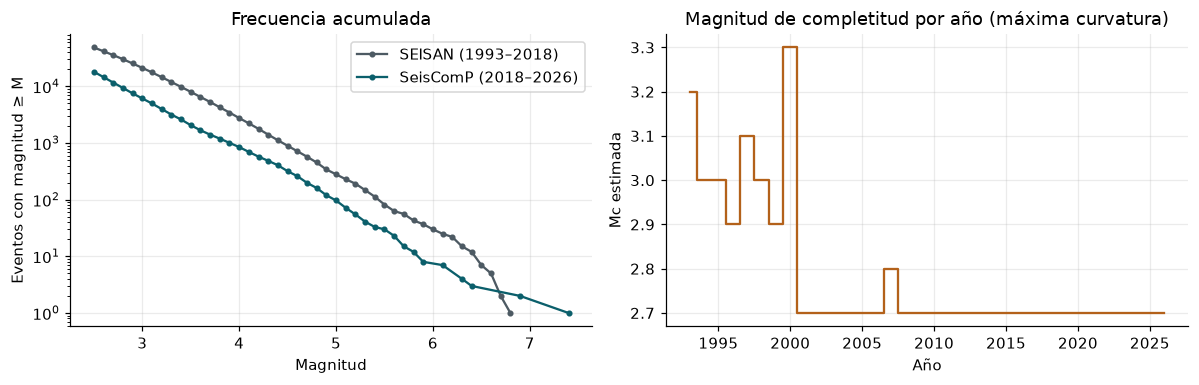

In [4]:
def mc_maxc(m):
    v, c = np.unique(np.round(m, 1), return_counts=True)
    return round(float(v[c.argmax()]) + 0.2, 1)

def b_value(m, mc):
    m = m[m >= mc - 1e-6]
    b = np.log10(np.e) / (m.mean() - (mc - 0.05))
    return b, b / np.sqrt(len(m)), len(m)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for label, d, color in [("SEISAN (1993–2018)", ev[ev.source.str.contains("SEISAN")], "#4d5a63"), ("SeisComP (2018–2026)", ev[~ev.source.str.contains("SEISAN")], "#0b5f6b")]:
    m = d.magnitude.to_numpy()
    v, c = np.unique(np.round(m, 1), return_counts=True)
    axes[0].semilogy(v, c[::-1].cumsum()[::-1], "o-", ms=3, color=color, label=label)
    mc = mc_maxc(m); b, se, n = b_value(m, mc)
    print(f"{label}: Mc ≈ {mc}, valor b = {b:.2f} ± {se:.2f} (n = {n})")
axes[0].set(xlabel="Magnitud", ylabel="Eventos con magnitud ≥ M", title="Frecuencia acumulada"); axes[0].legend()
ev.groupby("year").magnitude.apply(lambda s: mc_maxc(s.to_numpy())).plot(ax=axes[1], drawstyle="steps-mid", color="#b3611a")
axes[1].set(xlabel="Año", ylabel="Mc estimada", title="Magnitud de completitud por año (máxima curvatura)")
plt.tight_layout(); plt.show()

## 4. Tipos de magnitud

El catálogo mezcla varios tipos; no se homogeneizaron a Mw.

In [5]:
t = ev.magnitude_family.value_counts()
print((t / len(ev) * 100).round(2).astype(str) + " %")

magnitude_family
ML       72.88 %
MLr      26.01 %
M         0.46 %
Mw        0.38 %
M_MLr      0.1 %
MLv       0.06 %
M_Pac     0.05 %
mb        0.05 %
Name: count, dtype: str


## 5. Profundidad

La sismicidad colombiana tiene un componente intermedio muy marcado (nido de Bucaramanga, alrededor de 150 km).

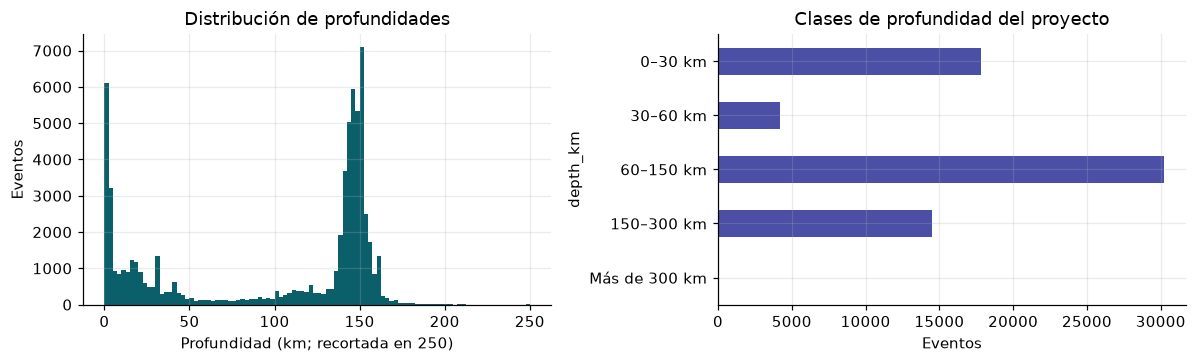

Sin profundidad: 241 · fijada en 0 km por la fuente: 4007


In [6]:
bins = [0, 30, 60, 150, 300, 1000]
labels = ["0–30 km", "30–60 km", "60–150 km", "150–300 km", "Más de 300 km"]
cls = pd.cut(ev.depth_km, bins=bins, labels=labels, right=False).value_counts().reindex(labels)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(ev.depth_km.dropna().clip(upper=250), bins=100, color="#0b5f6b")
axes[0].set(xlabel="Profundidad (km; recortada en 250)", ylabel="Eventos", title="Distribución de profundidades")
cls.plot(kind="barh", ax=axes[1], color="#4b4fa6"); axes[1].set(xlabel="Eventos", title="Clases de profundidad del proyecto"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()
print(f"Sin profundidad: {ev.depth_km.isna().sum()} · fijada en 0 km por la fuente: {(ev.depth_flag == 'fijada_en_0').sum()}")

## 6. Distribución espacial

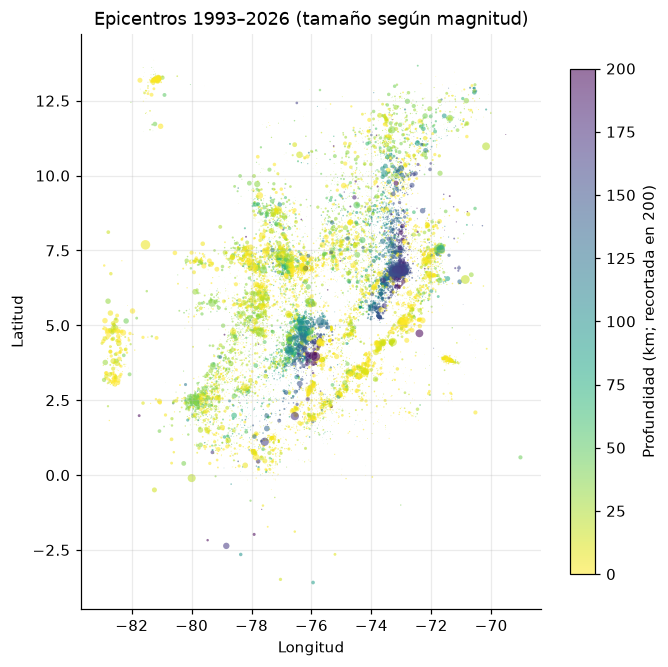

,eventos,m4,magnitud_max,prof_mediana
department,,,,
Santander,38802,1940,6.3,147.20
Antioquia,3028,130,5.3,5.40
Chocó,2986,187,7.4,39.88
Cundinamarca,1961,47,6.4,138.20
Valle del Cauca,1756,78,6.8,100.00
Meta,1754,89,6.1,4.10
Tolima,1489,61,5.6,16.08
Huila,1113,33,6.4,4.00
Boyacá,1111,44,6.6,16.30


In [7]:
fig, ax = plt.subplots(figsize=(6.2, 7))
d = ev.sort_values("magnitude")
sc = ax.scatter(d.longitude, d.latitude, s=(d.magnitude - 2.3) ** 2.4, c=d.depth_km.clip(upper=200), cmap="viridis_r", alpha=0.55, linewidths=0)
plt.colorbar(sc, ax=ax, label="Profundidad (km; recortada en 200)", shrink=0.7)
ax.set(xlabel="Longitud", ylabel="Latitud", title="Epicentros 1993–2026 (tamaño según magnitud)", aspect="equal")
plt.tight_layout(); plt.show()
top = ev[ev.department != ""].groupby("department").agg(eventos=("magnitude", "size"), m4=("magnitude", lambda s: (s >= 4).sum()), magnitud_max=("magnitude", "max"), prof_mediana=("depth_km", "median")).sort_values("eventos", ascending=False)
top.head(10)

## 7. Calidad de la localización a lo largo del tiempo

El código A–D es derivado en este proyecto (gap, error horizontal y RMS); no es un código oficial del SGC.

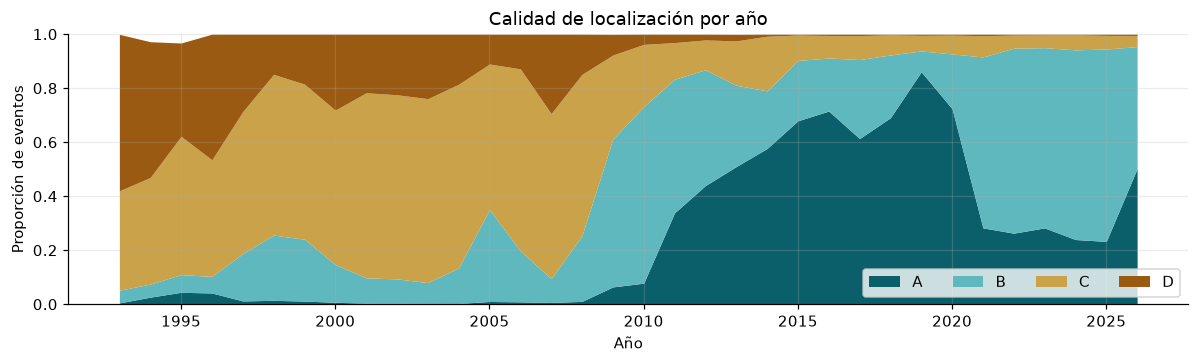

Error de localización mediano por década (km):
year
1990    15.6
2000    14.6
2010     4.5
2020     3.8


In [8]:
q = ev.groupby(["year", "quality_code"]).size().unstack(fill_value=0)
q = q.div(q.sum(axis=1), axis=0)[["A", "B", "C", "D"]]
ax = q.plot(kind="area", stacked=True, figsize=(11, 3.4), color=["#0b5f6b", "#5fb8be", "#c9a24a", "#9a5a12"], linewidth=0)
ax.set(xlabel="Año", ylabel="Proporción de eventos", title="Calidad de localización por año", ylim=(0, 1)); ax.legend(title="", ncol=4, loc="lower right")
plt.tight_layout(); plt.show()
print("Error de localización mediano por década (km):")
print(ev.groupby((ev.year // 10) * 10).location_error_km.median().round(1).to_string())

## 8. Rareza de los eventos según el umbral

Esto condiciona todo el modelado: para magnitudes altas hay muy pocos casos.

In [9]:
years = (ev.event_datetime_utc.max() - ev.event_datetime_utc.min()).days / 365.25
rows = [{"umbral": f"M ≥ {m:.1f}", "eventos": int((ev.magnitude >= m).sum()), "por año": round((ev.magnitude >= m).sum() / years, 1)} for m in (2.5, 3, 4, 5, 6)]
pd.DataFrame(rows)

,umbral,eventos,por año
0,M ≥ 2.5,66987,2008.1
1,M ≥ 3.0,27444,822.7
2,M ≥ 4.0,3622,108.6
3,M ≥ 5.0,378,11.3
4,M ≥ 6.0,37,1.1


## 9. La tabla zona-periodo y la línea base

Construimos la tabla para departamentos, 30 días y M ≥ 4,0, y comprobamos que las particiones son cronológicas.

In [10]:
import sys
sys.path.insert(0, str(ROOT / "pipeline"))
from sismonexo import modeling as M
from sismonexo.features import FEATURES, EventArrays, build_matrix, day_to_date

ea = EventArrays.from_frame(ev)
df = build_matrix(ea, "dep", 30, 4.0)
lab = df.y.notna()
print(f"{lab.sum():,} zonas-periodo con etiqueta · {int(df.y.sum()):,} con evento ({df.loc[lab, 'y'].mean():.2%}) · {len(FEATURES)} variables".replace(",", "."))
folds = M.make_folds(df.origin.to_numpy(), lab.to_numpy(), 30)
o = df.origin.to_numpy()
pd.DataFrame([{"bloque": f.k, "entrenamiento_hasta": day_to_date(o[f.train].max()).date(), "validación": f"{day_to_date(o[f.val].min()).date()} → {day_to_date(o[f.val].max()).date()}",
               "prueba": f"{day_to_date(o[f.test].min()).date()} → {day_to_date(o[f.test].max()).date()}", "separación_días": int(o[f.val].min() - o[f.train].max())} for f in folds])

13.002 zonas-periodo con etiqueta · 1.106 con evento (8.51%) · 24 variables


,bloque,entrenamiento_hasta,validación,prueba,separación_días
0,1,2016-08-04,2016-09-03 → 2018-08-24,2018-09-23 → 2019-08-19,30
1,2,2017-07-30,2017-08-29 → 2019-08-19,2019-09-18 → 2020-09-12,30
2,3,2018-08-24,2018-09-23 → 2020-09-12,2020-10-12 → 2021-09-07,30
3,4,2019-08-19,2019-09-18 → 2021-09-07,2021-10-07 → 2022-09-02,30
4,5,2020-08-13,2020-09-12 → 2022-09-02,2022-10-02 → 2023-08-28,30
5,6,2021-08-08,2021-09-07 → 2023-08-28,2023-09-27 → 2024-08-22,30
6,7,2022-08-03,2022-09-02 → 2024-08-22,2024-09-21 → 2025-08-17,30
7,8,2023-07-29,2023-08-28 → 2025-08-17,2025-09-16 → 2026-09-11,30


Línea base en el último bloque de prueba: PR-AUC 0.788 (prevalencia 0.068) · Brier 0.0300 · ROC-AUC 0.948


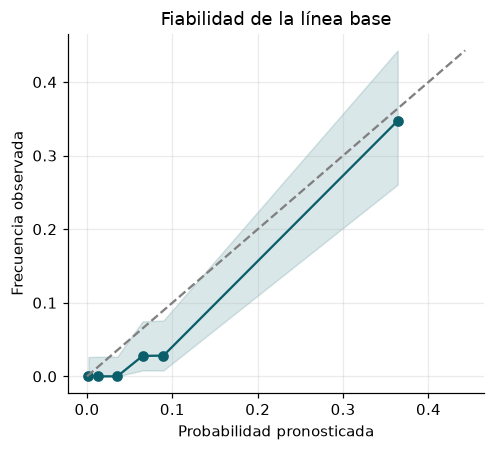

In [11]:
f = folds[-1]
tr, va, te = df.iloc[f.train], df.iloc[f.val], df.iloc[f.test]
base = M.Baseline(30).fit(tr, tr.y.to_numpy(), tr["count"].to_numpy())
p = base.predict(te)
m = M.metrics(te.y.to_numpy(), p, M.best_f1_threshold(va.y.to_numpy(), base.predict(va)))
print(f"Línea base en el último bloque de prueba: PR-AUC {m['pr_auc']:.3f} (prevalencia {m['prevalence']:.3f}) · Brier {m['brier']:.4f} · ROC-AUC {m['roc_auc']:.3f}")
rel = pd.DataFrame(M.reliability(te.y.to_numpy(), p, n_bins=6, min_n=30))
ax = rel.plot(x="p_mean", y="observed", marker="o", color="#0b5f6b", figsize=(4.6, 4.2), legend=False)
ax.fill_between(rel.p_mean, rel.lo, rel.hi, color="#0b5f6b", alpha=0.15); lim = max(rel.p_mean.max(), rel.hi.max())
ax.plot([0, lim], [0, lim], "--", color="gray"); ax.set(xlabel="Probabilidad pronosticada", ylabel="Frecuencia observada", title="Fiabilidad de la línea base")
plt.tight_layout(); plt.show()

## 10. Conclusiones del análisis exploratorio

- El catálogo es amplio pero **heterogéneo**: cambia de sistema en 2018, mejora la precisión de localización con los años y mezcla tipos de magnitud.
- La **completitud** está cerca del umbral de descarga; los conteos de eventos pequeños dependen de la red.
- Los eventos grandes son **muy escasos**, lo que limita cualquier modelo para M ≥ 5,0.
- La frecuencia histórica por zona ya es un pronóstico razonablemente calibrado: es la **línea base** que todo modelo debe superar.

El entrenamiento y la validación completos están en `pipeline/sismonexo/experiment.py` y se ejecutan con `python -m sismonexo.run_all`.